# Demand Forecasting and Inventory Optimization Using Machine Learning

## Week 1: Data Collection, Quality Checks & Exploratory Data Analysis

**Objective:** Understand the retail sales dataset, validate its quality, identify demand patterns, and prepare a reproducible dataset for subsequent forecasting and inventory optimization.

**Dataset:** M5 Forecasting Accuracy — Walmart retail sales data.

**Planned deliverables:**
1. Data dictionary
2. Source notes
3. Data-quality report
4. Cleaned interim dataset
5. Exploratory data analysis
6. Documented version-control workflow

In [1]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the datasets
calender = pd.read_csv('/content/calendar.csv')
sell_prices = pd.read_csv('/content/sell_prices.csv')
sales_train = pd.read_csv('/content/sales_train_validation.csv')

In [3]:
# Checking the shapes of dataset
print("Sales dataset shape:", sales_train.shape)
print("Calendar dataset shape:", calender.shape)
print("Prices dataset shape:", sell_prices.shape)

Sales dataset shape: (30490, 1919)
Calendar dataset shape: (1969, 14)
Prices dataset shape: (6841121, 4)


In [5]:
# Displaying first five rows of each dataset
print("Sales dataset :")
print(sales_train.head())
print("\nCalendar dataset :")
print(calender.head())
print("\nPrices dataset :")
print(sell_prices.head())

Sales dataset :
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  ...  d_1904  d_1905  d_1906  d_1907  d_1908  \
0       CA    0    0    0    0  ...       1       3       0       1       1   
1       CA    0    0    0    0  ...       0       0       0       0       0   
2       CA    0    0    0    0  ...       2       1       2       1       1   
3       CA    0    0    0    0  ...       1       0       5       4       1   
4       CA    0    0    0    0  ...       2       1       1       0       1   

   d_1909  d_1910  d_1911  d

In [9]:
# Checking column names of all datasets in list form
print("Sales dataset columns:", sales_train.columns.tolist())
print("Calendar dataset columns:", calender.columns.tolist())
print("Prices dataset columns:", sell_prices.columns.tolist())

Sales dataset columns: ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9', 'd_10', 'd_11', 'd_12', 'd_13', 'd_14', 'd_15', 'd_16', 'd_17', 'd_18', 'd_19', 'd_20', 'd_21', 'd_22', 'd_23', 'd_24', 'd_25', 'd_26', 'd_27', 'd_28', 'd_29', 'd_30', 'd_31', 'd_32', 'd_33', 'd_34', 'd_35', 'd_36', 'd_37', 'd_38', 'd_39', 'd_40', 'd_41', 'd_42', 'd_43', 'd_44', 'd_45', 'd_46', 'd_47', 'd_48', 'd_49', 'd_50', 'd_51', 'd_52', 'd_53', 'd_54', 'd_55', 'd_56', 'd_57', 'd_58', 'd_59', 'd_60', 'd_61', 'd_62', 'd_63', 'd_64', 'd_65', 'd_66', 'd_67', 'd_68', 'd_69', 'd_70', 'd_71', 'd_72', 'd_73', 'd_74', 'd_75', 'd_76', 'd_77', 'd_78', 'd_79', 'd_80', 'd_81', 'd_82', 'd_83', 'd_84', 'd_85', 'd_86', 'd_87', 'd_88', 'd_89', 'd_90', 'd_91', 'd_92', 'd_93', 'd_94', 'd_95', 'd_96', 'd_97', 'd_98', 'd_99', 'd_100', 'd_101', 'd_102', 'd_103', 'd_104', 'd_105', 'd_106', 'd_107', 'd_108', 'd_109', 'd_110', 'd_111', 'd_112', 'd_113', 'd_11

In [11]:
# Checking for missing values
print("SALES: Missing Values")
print(sales_train.isnull().sum().sum())  # Total missing values
print(sales_train.isnull().sum().sort_values(ascending=False).head(20))

print("\nCALENDAR: Missing Values")
print(calender.isnull().sum())

print("\nPRICES: Missing Values")
print(sell_prices.isnull().sum())

SALES: Missing Values
0
d_1913      0
id          0
item_id     0
dept_id     0
cat_id      0
store_id    0
state_id    0
d_1         0
d_2         0
d_3         0
d_4         0
d_5         0
d_6         0
d_7         0
d_8         0
d_1897      0
d_1896      0
d_1895      0
d_1894      0
d_1893      0
dtype: int64

CALENDAR: Missing Values
date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

PRICES: Missing Values
store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64


In [12]:
# Checking for duplicates
print("Sales duplicate rows:", sales_train.duplicated().sum())
print("Duplicate sales IDs:", sales_train["id"].duplicated().sum())

print("Calendar duplicate rows:", calender.duplicated().sum())
print("Duplicate calendar dates:", calender["date"].duplicated().sum())

print("Price duplicate rows:", sell_prices.duplicated().sum())
print("Duplicate price keys:", sell_prices.duplicated(
    subset=["store_id", "item_id", "wm_yr_wk"]).sum())

Sales duplicate rows: 0
Duplicate sales IDs: 0
Calendar duplicate rows: 0
Duplicate calendar dates: 0
Price duplicate rows: 0
Duplicate price keys: 0


In [13]:
# Checking for sales quantities
sales_cols = [col for col in sales_train.columns if col.startswith("d_")]

print("Negative sales:", (sales_train[sales_cols] < 0).sum().sum())
print("Zero sales:", (sales_train[sales_cols] == 0).sum().sum())
print("Missing sales:", sales_train[sales_cols].isna().sum().sum())

Negative sales: 0
Zero sales: 39777094
Missing sales: 0


In [14]:
# Checking for data coverage
calender["date"] = pd.to_datetime(calender["date"])

print("First date:", calender["date"].min())
print("Last date:", calender["date"].max())
print("Total calendar dates:", calender["date"].nunique())

all_dates = pd.date_range(calender["date"].min(), calender["date"].max(), freq="D")

print("Missing calendar dates:", len(all_dates.difference(calender["date"])))

First date: 2011-01-29 00:00:00
Last date: 2016-06-19 00:00:00
Total calendar dates: 1969
Missing calendar dates: 0


In [16]:
# Checking for product and data coverage
print("Unique products:", sales_train["item_id"].nunique())
print("Unique stores:", sales_train["store_id"].nunique())
print("Unique product-store series:", sales_train["id"].nunique())

print("\nSales rows per store:")
print(sales_train.groupby("store_id")["id"].count())

print("\nSales rows per category:")
print(sales_train.groupby("cat_id")["id"].count())

Unique products: 3049
Unique stores: 10
Unique product-store series: 30490

Sales rows per store:
store_id
CA_1    3049
CA_2    3049
CA_3    3049
CA_4    3049
TX_1    3049
TX_2    3049
TX_3    3049
WI_1    3049
WI_2    3049
WI_3    3049
Name: id, dtype: int64

Sales rows per category:
cat_id
FOODS        14370
HOBBIES       5650
HOUSEHOLD    10470
Name: id, dtype: int64


In [17]:
# Checking selling prices
print("Minimum price:", sell_prices["sell_price"].min())
print("Maximum price:", sell_prices["sell_price"].max())
print("Zero or negative prices:", (sell_prices["sell_price"] <= 0).sum())
print("Missing prices:", sell_prices["sell_price"].isna().sum())

print("\nUnique stores in prices:", sell_prices["store_id"].nunique())
print("Unique products in prices:", sell_prices["item_id"].nunique())

Minimum price: 0.01
Maximum price: 107.32
Zero or negative prices: 0
Missing prices: 0

Unique stores in prices: 10
Unique products in prices: 3049


In [18]:
# Checking for product store consistency
sales_keys = sales_train[["item_id", "store_id"]].drop_duplicates()
price_keys = sell_prices[["item_id", "store_id"]].drop_duplicates()

print("Sales product-store pairs:", len(sales_keys))
print("Price product-store pairs:", len(price_keys))

print("Pairs missing prices:", len(
    sales_keys.merge(
        price_keys,
        on=["item_id", "store_id"],
        how="left",
        indicator=True
    ).query("_merge == 'left_only'")
))

Sales product-store pairs: 30490
Price product-store pairs: 30490
Pairs missing prices: 0


In [19]:
# Checking weekly price coverage
sales_weeks = set(calender["wm_yr_wk"])
price_weeks = set(sell_prices["wm_yr_wk"])

print("Calendar weeks:", len(sales_weeks))
print("Price weeks:", len(price_weeks))
print("Calendar weeks without prices:", len(sales_weeks - price_weeks))

Calendar weeks: 282
Price weeks: 282
Calendar weeks without prices: 0


In [20]:
# Checking product store week-price coverage
sales_weeks = calender[["d", "wm_yr_wk"]]
sales_weeks = sales_weeks[sales_weeks["d"].isin(sales_train.columns)]

sales_weeks = sales_weeks.merge(
    calender[["d", "wm_yr_wk"]],
    on=["d", "wm_yr_wk"],
    how="left"
).drop_duplicates()

print("Sales dates mapped:", sales_weeks["d"].nunique())

Sales dates mapped: 1913


In [21]:
# Checking actual product store week-price coverage
# Convert sales data into product-store-date records
sales_long = sales_train.melt(
    id_vars=["id", "item_id", "store_id"],
    value_vars=[c for c in sales_train.columns if c.startswith("d_")],
    var_name="d",
    value_name="sales"
)

# Add calendar week
sales_long = sales_long.merge(calender[["d", "wm_yr_wk"]], on="d",how="left")

# Check matching prices
coverage = sales_long[
    ["item_id", "store_id", "wm_yr_wk"]
].drop_duplicates().merge(
    sell_prices[["item_id", "store_id", "wm_yr_wk"]],
    on=["item_id", "store_id", "wm_yr_wk"],
    how="left",
    indicator=True
)

print("Product-store-week combinations:", len(coverage))
print("Combinations without prices:", (coverage["_merge"] == "left_only").sum())

Product-store-week combinations: 8354260
Combinations without prices: 1757059


In [22]:
# Checking the missing price percentage
missing = (coverage["_merge"] == "left_only").sum()
total = len(coverage)

print("Missing-price combinations:", missing)
print("Total combinations:", total)
print("Missing-price percentage:", round(missing / total * 100, 2), "%")

Missing-price combinations: 1757059
Total combinations: 8354260
Missing-price percentage: 21.03 %


In [23]:
# Checking whether missing prices occur in a particular week
missing_keys = coverage[coverage["_merge"] == "left_only"]

print("Missing-price combinations by week:")
print(missing_keys["wm_yr_wk"].value_counts().head(10))

Missing-price combinations by week:
wm_yr_wk
11101    19558
11102    18515
11103    17971
11104    17691
11105    17457
11106    17156
11107    16889
11108    16686
11109    16537
11110    16345
Name: count, dtype: int64


In [24]:
# Checking when prices are available
print("First price week:", sell_prices["wm_yr_wk"].min())
print("Last price week:", sell_prices["wm_yr_wk"].max())

print("\nFirst sales week:", calender[
    calender["d"].isin(sales_train.columns)
]["wm_yr_wk"].min())

print("Last sales week:", calender[
    calender["d"].isin(sales_train.columns)
]["wm_yr_wk"].max())

First price week: 11101
Last price week: 11621

First sales week: 11101
Last sales week: 11613


In [25]:
# Checking missing daily periods per product-store series
sales_cols = [c for c in sales_train.columns if c.startswith("d_")]

print("Expected daily columns:", 1913)
print("Actual daily columns:", len(sales_cols))
print("Series with missing daily values:",
      sales_train[sales_cols].isna().any(axis=1).sum())

Expected daily columns: 1913
Actual daily columns: 1913
Series with missing daily values: 0


In [26]:
# Examining zero-sales frequency by product
sales_cols = [c for c in sales_train.columns if c.startswith("d_")]

sales_train["zero_days"] = (sales_train[sales_cols] == 0).sum(axis=1)

print("Average zero-sales days:", round(sales_train["zero_days"].mean(), 2))
print("Maximum zero-sales days:", sales_train["zero_days"].max())

display(sales_train[["id", "item_id", "store_id", "zero_days"]].head())

Average zero-sales days: 1304.59
Maximum zero-sales days: 1906


,id,item_id,store_id,zero_days
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,CA_1,1492
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,CA_1,1511
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,CA_1,1697
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,CA_1,617
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,CA_1,950


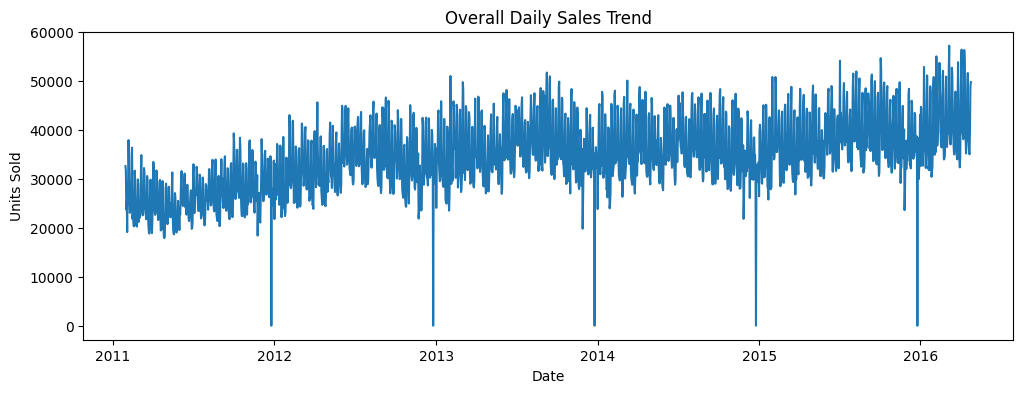

In [27]:
# Overall daily sales trend
sales_cols = [c for c in sales_train.columns if c.startswith("d_")]

daily_sales = sales_train[sales_cols].sum()

dates = calender.set_index("d").loc[daily_sales.index, "date"]

plt.figure(figsize=(12, 4))
plt.plot(dates, daily_sales.values)
plt.title("Overall Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.show()

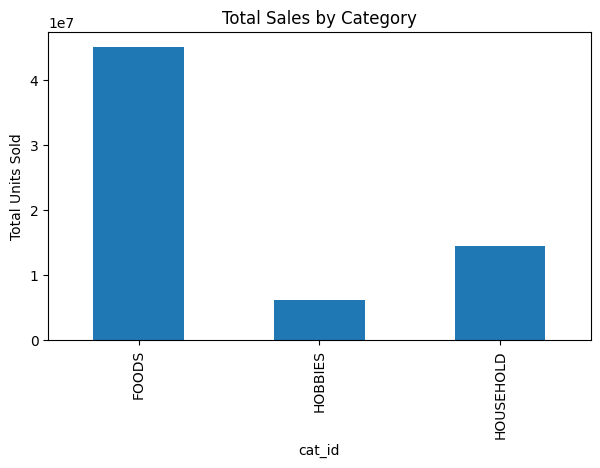

In [28]:
# Average sales by category
category_sales = sales_train.groupby("cat_id")[sales_cols].sum().sum(axis=1)

category_sales.plot(kind="bar", figsize=(7, 4), title="Total Sales by Category")
plt.ylabel("Total Units Sold")
plt.show()

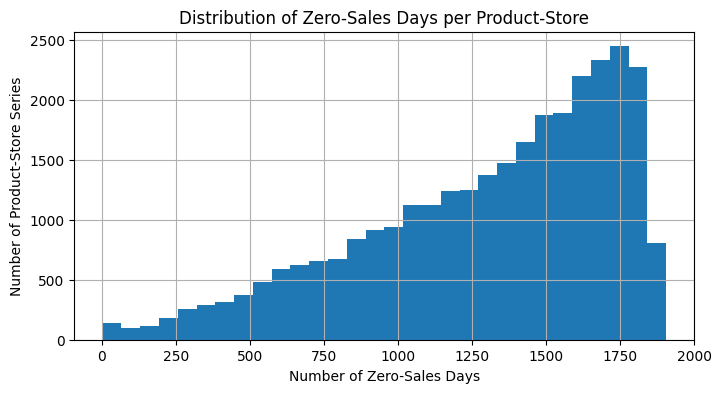

In [29]:
# Zero sales patterns
sales_train["zero_days"].hist(bins=30, figsize=(8, 4))
plt.title("Distribution of Zero-Sales Days per Product-Store")
plt.xlabel("Number of Zero-Sales Days")
plt.ylabel("Number of Product-Store Series")
plt.show()

### Week 1 – Exploratory Data Analysis Findings

1. **Sales trend:** Overall daily sales generally increase over the observation period from January 2011 to June 2016, with considerable day-to-day variation.
2. **Category contribution:** FOODS records the highest total sales, followed by HOUSEHOLD and HOBBIES.
3. **Zero-sales behavior:** Product-store series contain many zero-sales days, suggesting intermittent demand for numerous products.
4. **Data quality:** No missing values or duplicate rows were found in the sales dataset. Negative and missing daily sales quantities were also absent.
5. **Calendar coverage:** The calendar contains 1,969 unique dates, while the sales data contains 1,913 daily columns. All sales-day labels have corresponding calendar entries.
6. **Price coverage:** Approximately 21.03% of product-store-week combinations derived from the sales data have no matching price record. This issue should be documented and not automatically imputed.
7. **Limitations:** The available files do not provide complete inventory-on-hand or explicit stockout records. Therefore, zero sales cannot be confidently classified as zero demand or stockout-related lost sales.

**Overall conclusion:** The dataset is suitable for proceeding with the next stages of the project after documenting incomplete price coverage and the limitations of the available inventory information.